# Torus $\vee$ Circle

A stratified space $\mathbb{T}^{2} \vee S^{1}$ embedded in $\mathbb{R}^{3}$. Cup products partition the cohomology generators into two components; each stratum is fit separately and assembled into a piecewise-smooth map (Section 4 of the paper).


In [1]:
from dreimac import GeometryExamples, ToroidalCoords
from dreimac.utils import CircleMapUtils
from persim import plot_diagrams
from scipy.special import softmax
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from torofit.partition_utils import total_variation_scores
import torofit as TF
import numpy as np

pio.renderers.default = "notebook_connected"

In [2]:

np.random.seed(40)
torus = GeometryExamples.torus_3d(n_samples=2000, R=5, r=2)
theta = np.linspace(0,2*np.pi,num=1000)
circ_radius = 4
circle = circ_radius*np.column_stack([np.cos(theta), np.sin(theta), np.zeros_like(theta)])
circle[:,0] = circle[:,0] + (7 + circ_radius)
circle = circle +0.1* np.random.randn(circle.shape[0], circle.shape[1])
data = np.vstack([torus, circle])
fig = go.Figure(data=[go.Scatter3d(
    x=circle[:,0], y=circle[:,1], z=circle[:,2], 
    mode ='markers', 
    marker=dict(size = 1.5 , color='black')),
    go.Scatter3d(
    x=torus[:,0], y=torus[:,1], z=torus[:,2], 
    mode ='markers', 
    marker=dict(size = 1.5 , color='black'))])


fig.update_layout(
    width=1200, height=600,
    scene=dict(
        aspectratio=dict(x=4, y=2, z=1),
        camera=dict(eye=dict(x=0, y=-1, z=3)),
        xaxis=dict(
            showticklabels=False, # Hides the numerical labels
            ticks=""             # Hides the tick marks themselves
        ),
        yaxis=dict(
            showticklabels=False,
            ticks=""
        ),
        zaxis=dict(
            showticklabels=False,
            ticks=""
        )
    ),
    showlegend=False,
    font=dict(size=12)
)
fig.show()


In [3]:

# Create figure with better styling for papers
fig = go.Figure()

# Torus
fig.add_trace(go.Scatter3d(
    x=torus[:,0], y=torus[:,1], z=torus[:,2], 
    mode='markers', 
    marker=dict(size=2, color='#1f77b4', opacity=0.6),
    name='Torus'
))

# Circle
fig.add_trace(go.Scatter3d(
    x=circle[:,0], y=circle[:,1], z=circle[:,2], 
    mode='markers', 
    marker=dict(size=2, color='#ff7f0e', opacity=0.6),
    name='Circle'
))

fig.update_layout(
    width=800, height=800,
    scene=dict(
        aspectratio=dict(x=2, y=2, z=1),
        camera=dict(eye=dict(x=1.5, y=1.5, z=3)),
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False)
    ),
    showlegend=True,
    paper_bgcolor='white',
    font=dict(size=12)
)
fig.show()

In [4]:
tc = ToroidalCoords(data, n_landmarks=1000)
tc_theta = tc.get_coordinates(cocycle_idxs=[0,1,2])

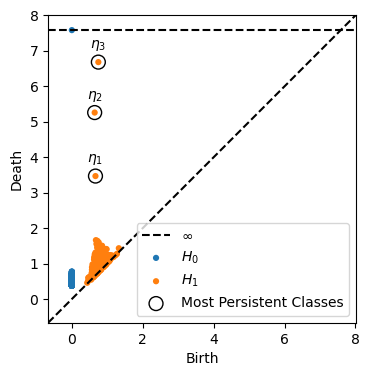

In [5]:
fig = plt.figure(figsize=(4,4))
ax = plt.gca()
dgms = tc._dgms
plot_diagrams(dgms, show=False, ax=ax)
perm = np.argsort(dgms[1][:,1] - dgms[1][:,0])
target_class = dgms[1][perm[-3:]]
ax.scatter(target_class[:,0], target_class[:,1], marker='o', color='red', s=100, label='Most Persistent Classes',  facecolors='none', edgecolors='black')
for i, c in enumerate(target_class):
    ax.annotate(rf'$\eta_{i+1}$', (c[0], c[1]), textcoords="offset points", xytext=(0,10), ha='center')
ax.legend()
plt.show()

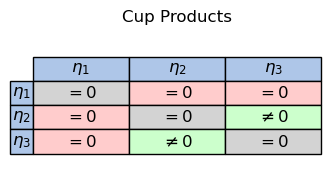

In [6]:
# For pipeline
fig_table, ax_table = plt.subplots(figsize=(4, 2))
ax_table.set_axis_off()

col_labels = [rf'$\eta_1$', rf'$\eta_2$', rf'$\eta_3$']
row_labels = [rf'$\eta_1$', rf'$\eta_2$', rf'$\eta_3$']
cell_text = [
    ['$= 0$',    '$= 0$',    '$= 0$'],
    ['$= 0$',    '$= 0$',    '$\\neq 0$'],
    ['$= 0$',    '$\\neq 0$', '$= 0$'],
]

table = ax_table.table(
    cellText=cell_text,
    rowLabels=row_labels,
    colLabels=col_labels,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.5, 1.5)

header_color  = '#AEC6E8'  # blue for headers
diagonal_color = '#D3D3D3' # gray for diagonal
zero_color     = '#FFCCCC' # red for = 0
nonzero_color  = '#CCFFCC' # green for ≠ 0

for (row, col), cell in table.get_celld().items():
    if row == 0 or col == -1:
        cell.set_facecolor(header_color)
    elif row - 1 == col:  # diagonal (1-indexed rows, 0-indexed cols)
        cell.set_facecolor(diagonal_color)
    elif '\\neq' in cell.get_text().get_text():
        cell.set_facecolor(nonzero_color)
    else:
        cell.set_facecolor(zero_color)

ax_table.set_title('Cup Products', fontsize=12)

plt.tight_layout()
plt.show()

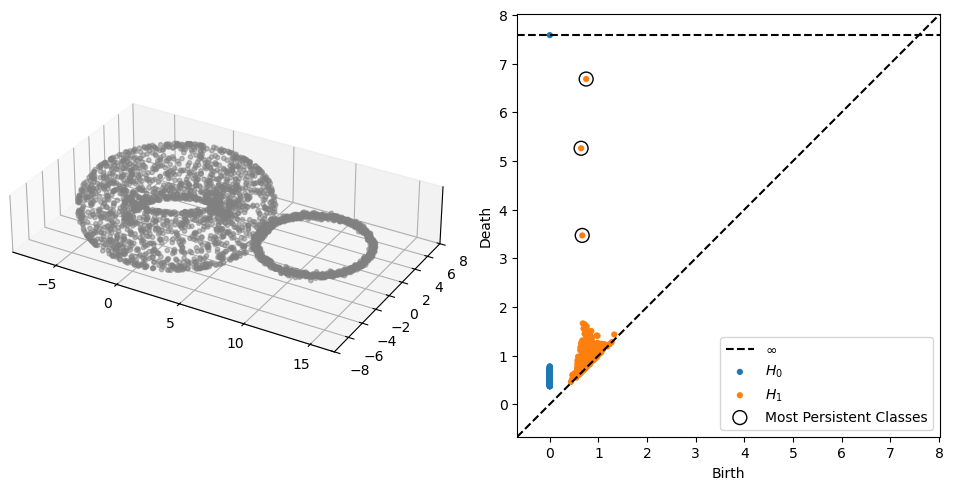

In [7]:
dgms = tc._dgms

fig = plt.figure(figsize=(12,6))
ax = [fig.add_subplot(1,2,1, projection='3d'), fig.add_subplot(1,2,2)]
ax[0].projection = '3d'
ax[0].scatter(data[:,0], data[:,1], data[:,2], s=10, color='gray', alpha=0.5)
ax[0].set_aspect('equal')
ax[0].set_zticks([])
plot_diagrams(dgms, show=False, ax=ax[1])
perm = np.argsort(dgms[1][:,1] - dgms[1][:,0])
target_class = dgms[1][perm[-3:]]
ax[1].scatter(target_class[:,0], target_class[:,1], marker='o', color='red', s=100, label='Most Persistent Classes',  facecolors='none', edgecolors='black')
ax[1].legend()


In [8]:
fig = go.Figure(data=[go.Scatter3d(
    x=data[:,0], y=data[:,1], z=data[:,2], 
    mode ='markers', 
    marker=dict(size = 1.5 , color=CircleMapUtils.to_sinebow(tc_theta[2])))])


fig.update_layout( width=900, height=900, scene=dict(aspectratio=dict(x=4, y=4, z=1)))
fig.show()

In [9]:
def find_partition_for_cocycle(tc, cocycle_idx, thresh=None, std_thresh=0.01):
    harm_reps = tc._harm_reps
    from dreimac.utils import CohomologyUtils
    thresh= tc._rips_threshold if thresh is None else thresh
    theta = CohomologyUtils.one_cocycle_to_matrix(dist_mat=tc._dist_land_land, 
                                                threshold=thresh,
                                                lookup_table=tc._cns_lookup_table,
                                                n_points = tc._n_landmarks,
                                                cocycle_as_vector=harm_reps[cocycle_idx])
    bad_idx = []
    good_idx = []
    #via standard deviation
    for i in range(len(theta)):
        vector = theta[i,:]
        nonzero_vector = vector[vector!=0]

        if len(nonzero_vector) == 0:
            bad_idx.append(i)
        else:
            diff = np.std(nonzero_vector)
            if diff <= std_thresh:
                bad_idx.append(i)
            else:
                good_idx.append(i)
    return good_idx, bad_idx


Points in torus 8
Points in Circle 898


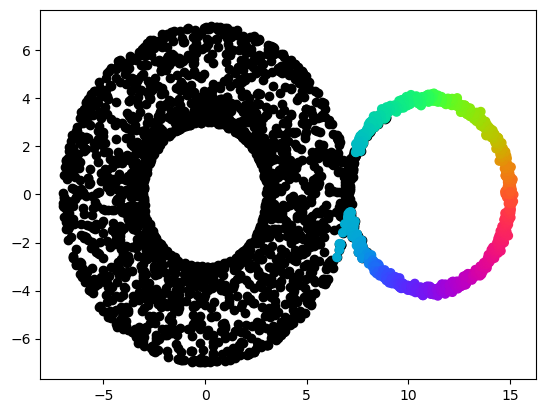

Points in torus 1906
Points in Circle 0


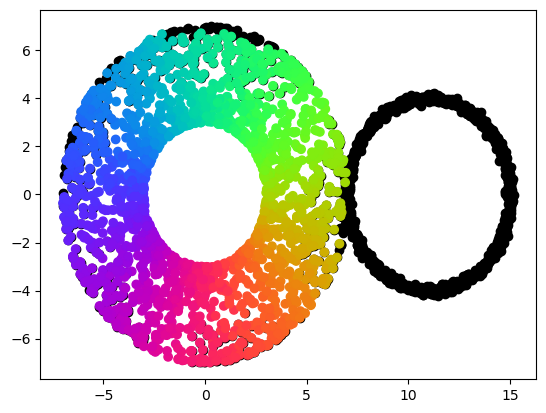

Points in torus 1995
Points in Circle 21


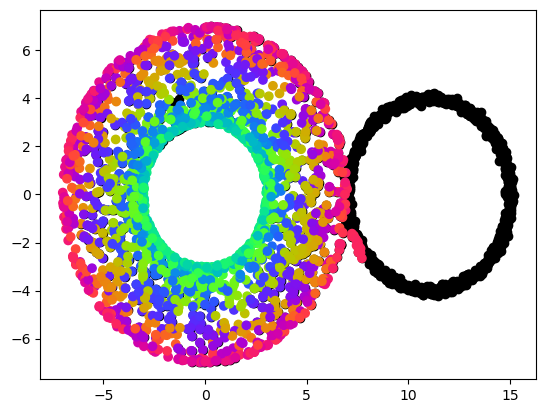

In [10]:
partition_thresh = [0.029, 0.03, 0.09]

for id in [0,1,2]:
    good_idx, bad_idx = find_partition_for_cocycle(tc, cocycle_idx=id, thresh=tc._rips_threshold, std_thresh=partition_thresh[id])
    landmarks = tc._idx_land
    good_landmarks = landmarks[good_idx]
    mems_for_good = tc._dist_land_data[good_idx, :]
    mems_for_bad = tc._dist_land_data[bad_idx, :]
    good_points = np.where(np.any(mems_for_good < tc._r_cover, axis=0))[0]
    bad_points = np.where(np.any(mems_for_bad < tc._r_cover, axis=0))[0]
    plt.scatter(data[bad_points,0], data[bad_points, 1], c= 'black')
    plt.scatter(data[good_points,0], data[good_points, 1], c = CircleMapUtils.to_sinebow(tc_theta[id][good_points]))
    print(f'Points in torus {len(np.where(good_points < 2000)[0])}')
    print(f'Points in Circle {len(np.where(good_points >= 2000)[0])}')
    
    plt.show()

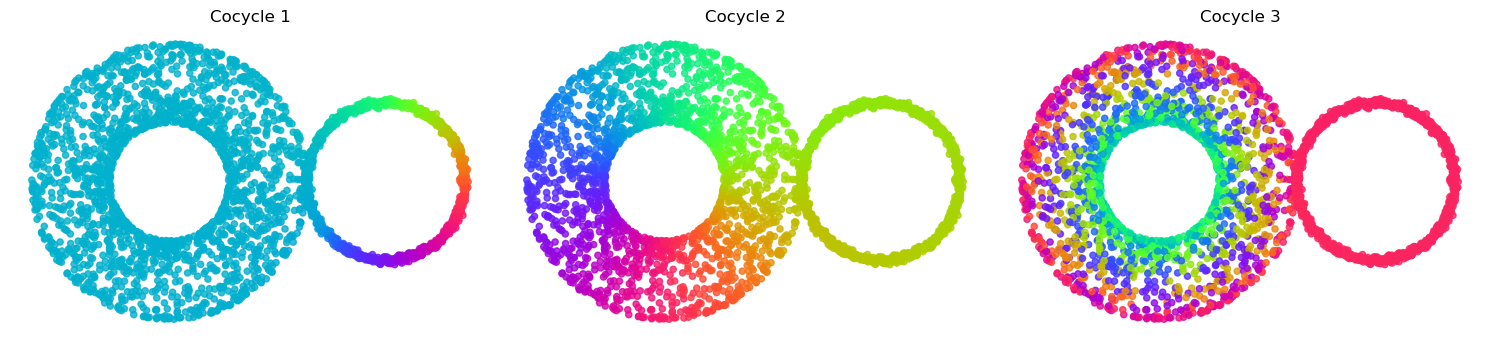

In [11]:
partition_thresh = [0.01, 0.03, 0.09]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for id, ax in enumerate(axes):
    

    ax.scatter(data[:, 0], data[:, 1], 
               c=CircleMapUtils.to_sinebow(tc_theta[id]), 
               s=20, alpha=0.8)
    
    ax.set_title(f'Cocycle {id+1}', fontsize=12)
    ax.set_aspect('equal')
    ax.axis('off')  # or keep axes depending on preference

plt.tight_layout()
plt.show()

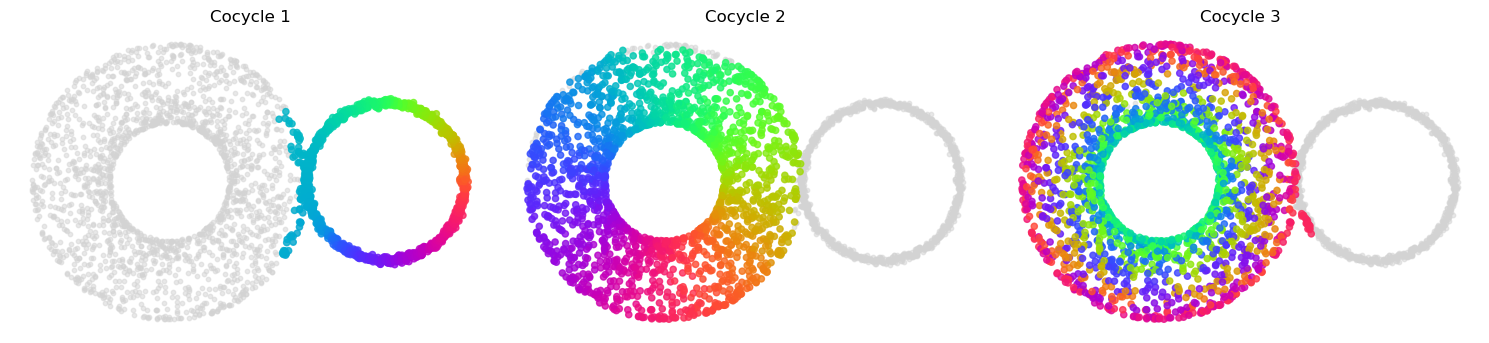

In [12]:
partition_thresh = [0.01, 0.03, 0.09]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for id, ax in enumerate(axes):
    good_idx, bad_idx = find_partition_for_cocycle(
        tc, cocycle_idx=id, thresh=tc._rips_threshold, 
        std_thresh=partition_thresh[id]
    )
    
    landmarks = tc._idx_land
    good_landmarks = landmarks[good_idx]
    mems_for_good = tc._dist_land_data[good_idx, :]
    mems_for_bad = tc._dist_land_data[bad_idx, :]
    
    good_points = np.where(np.any(mems_for_good < tc._r_cover, axis=0))[0]
    bad_points = np.where(np.any(mems_for_bad < tc._r_cover, axis=0))[0]
    
    # Plot with better aesthetics
    ax.scatter(data[bad_points, 0], data[bad_points, 1], 
               c='lightgray', s=10, alpha=0.5, label='Rejected')
    ax.scatter(data[good_points, 0], data[good_points, 1], 
               c=CircleMapUtils.to_sinebow(tc_theta[id][good_points]), 
               s=20, alpha=0.8)
    
    ax.set_title(f'Cocycle {id+1}', fontsize=12)
    ax.set_aspect('equal')
    ax.axis('off')  # or keep axes depending on preference

plt.tight_layout()
plt.show()

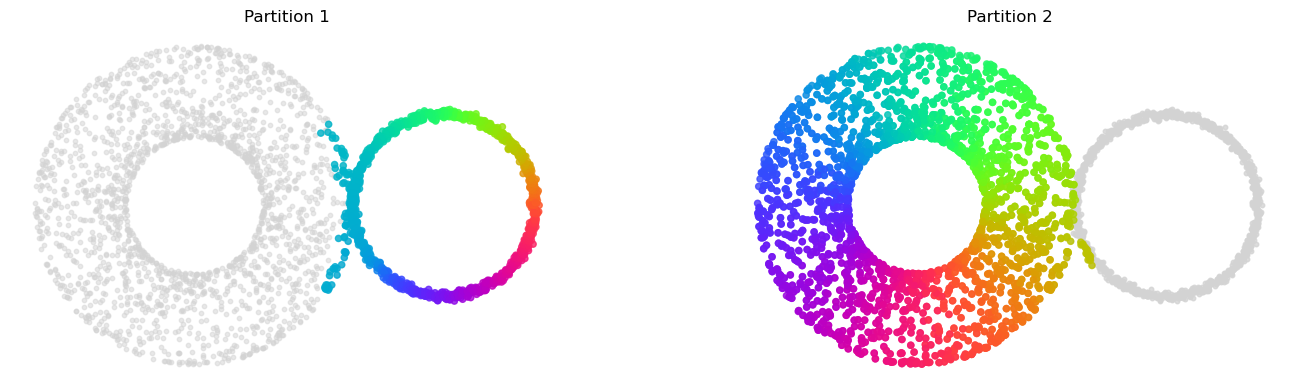

In [13]:
partition_thresh = [0.01, 0.03, 0.09]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
cocycle_partitions = [[0],[1,2]]
for part_id, cocycle_ids in enumerate(cocycle_partitions):
    ax = axes[part_id]
    good_points = np.asarray([]).astype(np.int64)
    bad_points = np.asarray([]).astype(np.int64)
    for i in cocycle_ids:
        good_idx, bad_idx = find_partition_for_cocycle(
            tc, cocycle_idx=i, thresh=tc._rips_threshold, 
            std_thresh=partition_thresh[i]
        )
        landmarks = tc._idx_land
        good_landmarks = landmarks[good_idx]
        mems_for_good = tc._dist_land_data[good_idx, :]
        mems_for_bad = tc._dist_land_data[bad_idx, :]
        
        good_points_cocycle = np.where(np.any(mems_for_good < tc._r_cover, axis=0))[0]
        bad_points_cocycle = np.where(np.any(mems_for_bad < tc._r_cover, axis=0))[0]
        
        good_points = np.append(good_points, good_points_cocycle) #Need union here
        bad_points = np.append(bad_points, bad_points_cocycle)
    
    # Plot with better aesthetics
    ax.scatter(data[bad_points, 0], data[bad_points, 1], 
               c='lightgray', s=10, alpha=0.5, label='Rejected')
    ax.scatter(data[good_points, 0], data[good_points, 1], 
               c=CircleMapUtils.to_sinebow(tc_theta[cocycle_ids[0]][good_points]), 
               s=20, alpha=0.8)
    
    ax.set_title(f'Partition {part_id + 1}', fontsize=12)
    ax.set_aspect('equal')
    ax.axis('off')  # or keep axes depending on preference

plt.tight_layout()
plt.show()

In [14]:



def find_fits(data,
            tc_theta,
            cocycle_partitions=[[0]],
            Ks=None, 
            lams=None,
            partition_thresh=[0.01]):
    if Ks is None:
        Ks = 5*np.ones(len(cocycle_partitions))
    if lams is None:
        lams = np.ones(len(cocycle_partitions))
    

    fits = []
    for part_id, cocycle_ids in enumerate(cocycle_partitions):
        print(f'partition{cocycle_ids}')
        good_points = np.asarray([]).astype(np.int64)
        bad_points = np.asarray([]).astype(np.int64)
        for i in cocycle_ids:
            good_idx, bad_idx = find_partition_for_cocycle(
            tc, cocycle_idx=i, thresh=tc._rips_threshold, 
            std_thresh=partition_thresh[i]
        )
        
            landmarks = tc._idx_land
            good_landmarks = landmarks[good_idx]
            mems_for_good = tc._dist_land_data[good_idx, :]
            mems_for_bad = tc._dist_land_data[bad_idx, :]
            
            good_points_cocycle = np.where(np.any(mems_for_good < tc._r_cover, axis=0))[0]
            bad_points_cocycle = np.where(np.any(mems_for_bad < tc._r_cover, axis=0))[0]
            
            good_points = np.append(good_points, good_points_cocycle) #Need union here
            bad_points = np.append(bad_points, bad_points_cocycle)
        plt.scatter(data[good_points,0], data[good_points,1])
        plt.show()
        coords = np.column_stack([tc_theta[i][good_points] for i in cocycle_ids])
        fit = TF.fit(data[good_points], coords, K = Ks[part_id], lam=lams[part_id])
        fits.append(fit)
    return fits

partition[0]


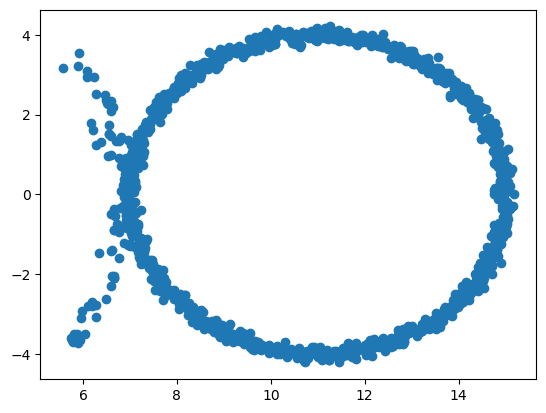

partition[1, 2]


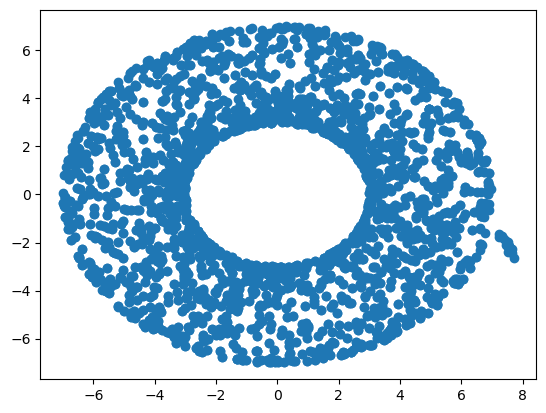

In [15]:
fits = find_fits(data, tc_theta, cocycle_partitions=[[0],[1,2]], Ks=[20,20], lams=[10.0, 10.0], partition_thresh=[0.01, 0.03, 0.09])
torus_fit = fits[1]
circle_fit = fits[0]

In [16]:
image, triangles = TF.plot_fitted_torus_via_coeff_matrix(torus_fit, K=20,samples=100)
res2 = TF.plot_fitted_circle_via_coeff_matrix(circle_fit,K=20, samples=100)
fig = go.Figure(data=[ go.Scatter3d(
    x=data[:,0], y=data[:,1], z=data[:,2], 
    mode ='markers', 
    marker=dict(size = 2 , color='gray', opacity=0.6),
    name='Data'),
    go.Mesh3d(x=image[:,0], 
                                y=image[:,1], 
                                z=image[:,2], 
                                color='#1f77b4', 
                                opacity=0.50,
                                i=triangles[:,0],
                                j=triangles[:,1],
                                k=triangles[:,2],
                                name='Torus',
                                showlegend=True),
     go.Scatter3d(
    x=res2[:,0], y=res2[:,1], z=res2[:,2], 
    mode ='lines', 
    line=dict(width = 8 , color='#ff7f0e'),
    name='Circle')
    ])


fig.update_layout(
    width=800, height=800,
    scene=dict(
        aspectratio=dict(x=2, y=2, z=1),
        camera=dict(eye=dict(x=1.5, y=-1.5, z=3)),
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False)
    ),
    showlegend=True,
    paper_bgcolor='white',
    font=dict(size=12)
)
fig.show()

In [17]:

part1 = total_variation_scores(0, tc, tc_theta)
part2 = total_variation_scores([1,2], tc, tc_theta)

raw_scores = np.column_stack([part1, part2])
softmax_scores = softmax(raw_scores, axis=1)
print(softmax_scores)
thresh = [0.5, 0.55]
parts = []
for i in range(raw_scores.shape[1]):
    print(f'Partition {i+1}, threshold: {thresh[i]}')
    good_idx = np.where(softmax_scores[:,i] >= thresh[i])[0]
    landmarks = tc._idx_land
    good_landmarks = landmarks[good_idx]
    mems_for_good = tc._dist_land_data[good_idx, :]
    parts.append(np.where(np.any(mems_for_good < tc._r_cover, axis=0))[0])

[[0.41588963 0.58411037]
 [0.59521974 0.40478026]
 [0.42973831 0.57026169]
 ...
 [0.40901377 0.59098623]
 [0.48785103 0.51214897]
 [0.44575444 0.55424556]]
Partition 1, threshold: 0.5
Partition 2, threshold: 0.55


In [18]:
tc_theta[1:,:].shape

(2, 3000)

In [19]:
Ks = [10,10]
lams=[40.0, 10.0]
torus_fit = TF.fit(data[parts[1]], tc_theta[1:,:][:,parts[1]].T, K=Ks[1], lam=lams[1])
circle_fit = TF.fit(data[parts[0]], tc_theta[0][parts[0]], K=Ks[0], lam=lams[0])

In [20]:
image, triangles = TF.plot_fitted_torus_via_coeff_matrix(torus_fit, K=Ks[0],samples=100)
res2 = TF.plot_fitted_circle_via_coeff_matrix(circle_fit,K=Ks[1], samples=100)
fig = go.Figure(data=[ go.Scatter3d(
    x=data[:,0], y=data[:,1], z=data[:,2], 
    mode ='markers', 
    marker=dict(size = 2 , color='gray', opacity=0.6),
    name='Data'),
    go.Mesh3d(x=image[:,0] +0.1, 
                                y=image[:,1], 
                                z=image[:,2], 
                                color='#1f77b4', 
                                opacity=0.50,
                                i=triangles[:,0],
                                j=triangles[:,1],
                                k=triangles[:,2],
                                name='Torus',
                                showlegend=True),
     go.Scatter3d(
    x=res2[:,0]-0.05, y=res2[:,1], z=res2[:,2], 
    mode ='lines', 
    line=dict(width = 8 , color='#ff7f0e'),
    name='Circle')
    ])


fig.update_layout(
    width=1200, height=600,
    scene=dict(
        aspectratio=dict(x=4, y=2, z=1),
        camera=dict(eye=dict(x=0, y=-1, z=3)),
        xaxis=dict(
            showticklabels=False, # Hides the numerical labels
            ticks=""             # Hides the tick marks themselves
        ),
        yaxis=dict(
            showticklabels=False,
            ticks=""
        ),
        zaxis=dict(
            showticklabels=False,
            ticks=""
        )
    ),
    showlegend=True,
    font=dict(size=12)
)

fig.show()